In [1]:
import duckdb as ddb

In [48]:
from pprint import pprint

In [2]:
!ls ../../_data/lmnr_spans_and_traces/

spans_full.csv  traces_full.csv


In [3]:
spans_csv = "../../_data/lmnr_spans_and_traces/spans_full.csv"
traces_csv = "../../_data/lmnr_spans_and_traces/traces_full.csv"

In [25]:
lmnr_project_id = "13ab3ba5-eae1-4b7c-8dcb-760980264d89"

In [31]:
ddb.query(f"""
CREATE TABLE spans AS
    SELECT * FROM read_csv('{spans_csv}', max_line_size=4000000) WHERE project_id = '{lmnr_project_id}'
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [65]:
ddb.query(f"""
CREATE TABLE traces AS
    SELECT * FROM read_csv('{traces_csv}', max_line_size=4000000) WHERE project_id = '{lmnr_project_id}'
""")

In [32]:
ddb.query("SELECT COUNT(1) FROM spans")

┌──────────┐
│ count(1) │
│  int64   │
├──────────┤
│   311480 │
└──────────┘

In [66]:
ddb.query("SELECT COUNT(1) FROM traces")

┌──────────┐
│ count(1) │
│  int64   │
├──────────┤
│     5727 │
└──────────┘

In [70]:
ddb.query("DESCRIBE spans").to_df().to_latex()

'\\begin{tabular}{lllllll}\n\\toprule\n & column_name & column_type & null & key & default & extra \\\\\n\\midrule\n0 & span_id & VARCHAR & YES & NaN & NaN & NaN \\\\\n1 & name & VARCHAR & YES & NaN & NaN & NaN \\\\\n2 & span_type & BIGINT & YES & NaN & NaN & NaN \\\\\n3 & start_time & TIMESTAMP & YES & NaN & NaN & NaN \\\\\n4 & end_time & TIMESTAMP & YES & NaN & NaN & NaN \\\\\n5 & input_cost & DOUBLE & YES & NaN & NaN & NaN \\\\\n6 & output_cost & DOUBLE & YES & NaN & NaN & NaN \\\\\n7 & total_cost & DOUBLE & YES & NaN & NaN & NaN \\\\\n8 & model & VARCHAR & YES & NaN & NaN & NaN \\\\\n9 & session_id & VARCHAR & YES & NaN & NaN & NaN \\\\\n10 & project_id & VARCHAR & YES & NaN & NaN & NaN \\\\\n11 & trace_id & VARCHAR & YES & NaN & NaN & NaN \\\\\n12 & provider & VARCHAR & YES & NaN & NaN & NaN \\\\\n13 & input_tokens & BIGINT & YES & NaN & NaN & NaN \\\\\n14 & output_tokens & BIGINT & YES & NaN & NaN & NaN \\\\\n15 & total_tokens & BIGINT & YES & NaN & NaN & NaN \\\\\n16 & user_id &

In [85]:
ddb.query("DESCRIBE traces").to_df()

,column_name,column_type,null,key,default,extra
0,id,VARCHAR,YES,None,None,None
1,project_id,VARCHAR,YES,None,None,None
2,start_time,TIMESTAMP,YES,None,None,None
3,end_time,TIMESTAMP,YES,None,None,None
4,duration,DOUBLE,YES,None,None,None
5,input_tokens,BIGINT,YES,None,None,None
6,output_tokens,BIGINT,YES,None,None,None
7,total_tokens,BIGINT,YES,None,None,None
8,input_cost,DOUBLE,YES,None,None,None
9,output_cost,DOUBLE,YES,None,None,None


In [35]:
ddb.query("SELECT parent_span_id, COUNT(1) FROM spans GROUP BY 1 ORDER BY 2 DESC").to_df().describe()

,count(1)
count,113105.000000
mean,2.753901
std,19.378052
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,5680.000000


In [36]:
ddb.query("SELECT project_id, session_id, path FROM spans LIMIT 10").to_df()

,project_id,session_id,path
0,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
1,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
2,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
3,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
4,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
5,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
6,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
7,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.openai.chat
8,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...
9,13ab3ba5-eae1-4b7c-8dcb-760980264d89,c_83-x-s_8--full-eml-data-focus-openai-platfor...,c_83-x-s_8.LangGraph.workflow.run_metadata_der...


In [37]:
ddb.query("SELECT DISTINCT project_id FROM spans")

┌──────────────────────────────────────┐
│              project_id              │
│               varchar                │
├──────────────────────────────────────┤
│ 13ab3ba5-eae1-4b7c-8dcb-760980264d89 │
└──────────────────────────────────────┘

In [53]:
ddb.query("SELECT DISTINCT session_id FROM spans").to_df()

,session_id
0,c_32-x-s_0--full-dwc-data-focus-openai-platfor...
1,c_122-x-s_0--full-dwc-data-focus-openai-platfo...
2,c_162-x-s_4--full-dwc-author-focus-openai-plat...
3,c_20-x-s_4--full-dwc-author-focus-openai-platf...
4,c_62-x-s_4--full-dwc-author-focus-openai-platf...
...,...
783,c_0-x-s_5--full-dwc-author-focus-surf-{'provid...
784,c_77-x-s_8--full-eml-data-focus-openai-platfor...
785,c_14-x-s_8--full-eml-data-focus-openai-platfor...
786,c_15-x-s_4--full-dwc-author-focus-openai-platf...


In [57]:
ddb.query("SELECT DISTINCT session_id FROM spans WHERE session_id ^@ 'c_'").to_df()

,session_id
0,c_32-x-s_0--full-dwc-data-focus-openai-platfor...
1,c_122-x-s_0--full-dwc-data-focus-openai-platfo...
2,c_162-x-s_4--full-dwc-author-focus-openai-plat...
3,c_20-x-s_4--full-dwc-author-focus-openai-platf...
4,c_62-x-s_4--full-dwc-author-focus-openai-platf...
...,...
758,c_111-x-s_0--full-dwc-data-focus-openai-platfo...
759,c_167-x-s_8--full-eml-data-focus-openai-platfo...
760,c_87-x-s_12--full-eml-author-focus-openai-plat...
761,c_57-x-s_8--full-eml-data-focus-openai-platfor...


In [51]:
pprint(dict(next(ddb.query("SELECT DISTINCT session_id FROM spans WHERE session_id ^@ 'c_'").to_df().iterrows())[1]))

{'session_id': "c_79-x-s_8--full-eml-data-focus-openai-platform-{'provider': "
               "'openai-platform', 'core_platform': 'openai', "
               "'proxy_platform': 'openai', 'core_llm': 'gpt-5.4-mini', "
               "'embedding_model': 'text-embedding-3-small', 'rag_llm': "
               "'gpt-5.4-mini'}"}


In [60]:
ddb.query("SELECT trace_id, COUNT(1) FROM spans WHERE session_id ^@ 'c_' GROUP BY 1").to_df().describe()

,count(1)
count,799.000000
mean,344.612015
std,331.078892
min,3.000000
25%,54.000000
50%,111.000000
75%,673.500000
max,1454.000000


In [64]:
ddb.query("SELECT trace_id, session_id, COUNT(1) FROM spans WHERE session_id ^@ 'c_' GROUP BY 1,2 ORDER BY 1").to_df().describe(include="all")

,trace_id,session_id,count(1)
count,799,799,799.000000
unique,799,763,NaN
top,001d31da-0034-8c82-f835-4c12ed1ae823,c_0-x-s_16--ablation-dwc-data-focus-openai-pla...,NaN
freq,1,5,NaN
mean,NaN,NaN,344.612015
std,NaN,NaN,331.078892
min,NaN,NaN,3.000000
25%,NaN,NaN,54.000000
50%,NaN,NaN,111.000000
75%,NaN,NaN,673.500000


In [69]:
ddb.query("SELECT id, session_id, COUNT(1) FROM traces WHERE session_id ^@ 'c_' GROUP BY 1,2 ORDER BY 1").to_df().describe(include="all")

,id,session_id,count(1)
count,799,799,799.0
unique,799,763,NaN
top,001d31da-0034-8c82-f835-4c12ed1ae823,c_0-x-s_16--ablation-dwc-data-focus-openai-pla...,NaN
freq,1,5,NaN
mean,NaN,NaN,1.0
std,NaN,NaN,0.0
min,NaN,NaN,1.0
25%,NaN,NaN,1.0
50%,NaN,NaN,1.0
75%,NaN,NaN,1.0


In [74]:
ddb.query("SELECT name, COUNT(1) FROM spans WHERE session_id ^@ 'c_' GROUP BY 1 ORDER BY 1").to_df()

,name,count(1)
0,ChatOpenAI.chat,49376
1,JsonOutputParser.task,6979
2,LangGraph.task,11392
3,__start__.task,6261
4,_is_ground_truth_metadata_given.task,794
...,...,...
797,tool_or_cleanup.task,10591
798,tool_or_exit.task,28
799,tool_or_finalize.task,7547
800,tools.task,13604


In [87]:
ddb.query("""
SELECT DISTINCT status FROM traces;
""")

┌─────────┐
│ status  │
│ varchar │
├─────────┤
│ error   │
│ NULL    │
└─────────┘

In [94]:
ddb.query("""
SELECT s.name, s.trace_id, s.session_id, t.status, COUNT(1) 

FROM spans s
JOIN 
    traces t 
    ON s.trace_id = t.id

WHERE 
    s.session_id ^@ 'c_' 
AND 
    s.name ^@ 'call_explorer_agent'

GROUP BY 1,2,3,4
ORDER BY 1
""").to_df().describe(include="all")

,name,trace_id,session_id,status,count(1)
count,375,375,375,36,375.000000
unique,1,375,361,1,NaN
top,call_explorer_agent.task,fa9a60cc-ecf9-8ad7-2224-3a6c5b148972,c_1-x-s_0--full-dwc-data-focus-openai-platform...,error,NaN
freq,375,1,4,36,NaN
mean,NaN,NaN,NaN,NaN,28.333333
std,NaN,NaN,NaN,NaN,27.539924
min,NaN,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,NaN,3.000000
50%,NaN,NaN,NaN,NaN,14.000000
75%,NaN,NaN,NaN,NaN,54.500000


In [103]:
ddb.query("""
SELECT s.name, s.session_id, COALESCE(t.status, 'OK') AS status, COUNT(1) 

FROM spans s
JOIN 
    traces t 
    ON s.trace_id = t.id

WHERE 
    s.session_id ^@ 'c_' 
AND 
    s.name ^@ 'call_interviewer_agent'

GROUP BY 1,2,3
ORDER BY 1
""").to_df().groupby("status").describe(include="all")

name                                                               \
       count unique                          top freq mean  std  min  25%   
status                                                                      
OK       333      1  call_interviewer_agent.task  333  NaN  NaN  NaN  NaN   
error     27      1  call_interviewer_agent.task   27  NaN  NaN  NaN  NaN   

                  ... count(1)                                            \
        50%  75%  ...   unique top freq       mean        std  min   25%   
status            ...                                                      
OK      NaN  NaN  ...      NaN NaN  NaN  20.534535  19.193910  1.0   3.0   
error   NaN  NaN  ...      NaN NaN  NaN  26.333333  14.098554  2.0  22.0   

                          
         50%   75%   max  
status                    
OK       5.0  39.0  69.0  
error   27.0  33.5  59.0  

[2 rows x 33 columns]

In [111]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x5e14356d0>,
 'caps': [<matplotlib.lines.Line2D at 0x5e1435950>,
 'boxes': [<matplotlib.lines.Line2D at 0x5e1435590>],
 'medians': [<matplotlib.lines.Line2D at 0x5e1435bd0>],
 'fliers': [<matplotlib.lines.Line2D at 0x5e1435d10>],
 'means': []}

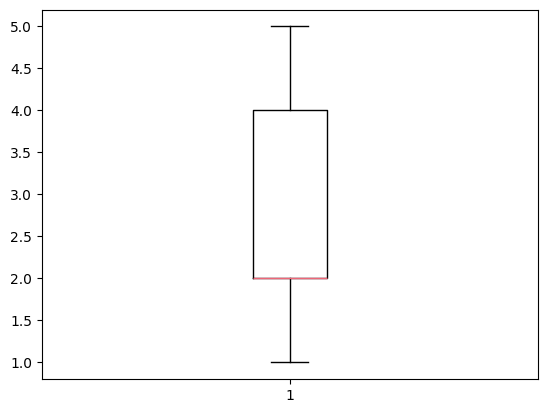

In [113]:
counts = ddb.query("""
SELECT s.name, s.parent_span_id, s.session_id, COALESCE(t.status, 'OK') AS status, COUNT(1) as cnt

FROM spans s
JOIN 
    traces t 
    ON s.trace_id = t.id

WHERE 
    s.session_id ^@ 'c_' 
AND 
    s.name ^@ 'call_interviewer_agent'

GROUP BY 1,2,3,4
ORDER BY 1
""").to_df()["cnt"]

plt.boxplot(counts)

{'whiskers': [<matplotlib.lines.Line2D at 0x5e2595a90>,
 'caps': [<matplotlib.lines.Line2D at 0x5e2595d10>,
 'boxes': [<matplotlib.lines.Line2D at 0x5e2595950>],
 'medians': [<matplotlib.lines.Line2D at 0x5e2595f90>],
 'fliers': [<matplotlib.lines.Line2D at 0x5e25960d0>],
 'means': []}

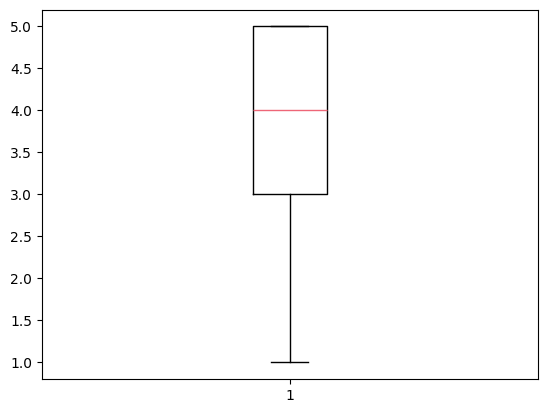

In [120]:
counts = ddb.query("""
SELECT s.name, s.parent_span_id, s.session_id, COALESCE(t.status, 'OK') AS status, COUNT(1) AS cnt

FROM spans s
JOIN 
    traces t 
    ON s.trace_id = t.id

WHERE 
    s.session_id ^@ 'c_' 
AND 
    s.name ^@ 'call_explorer_agent'

GROUP BY 1,2,3,4
ORDER BY 1
""").to_df()["cnt"]

plt.boxplot(counts)

In [124]:
import json

In [135]:
sample_output = next(ddb.query("""
SELECT DISTINCT s.output
FROM spans s
WHERE 
    s.session_id ^@ 'c_' 
AND 
    s.name ^@ 'call_explorer_agent'
ORDER BY s.span_id
""").to_df().iterrows())

json.loads(json.loads(sample_output[1]["output"]))

{'outputs': {'messages': [{'lc': 1,
    'type': 'constructor',
    'id': ['langchain', 'schema', 'messages', 'AIMessage'],
    'kwargs': {'content': '',
     'additional_kwargs': {'refusal': None},
     'response_metadata': {'token_usage': {'completion_tokens': 61,
       'prompt_tokens': 1834,
       'total_tokens': 1895,
       'completion_tokens_details': {'accepted_prediction_tokens': 0,
        'audio_tokens': 0,
        'reasoning_tokens': 0,
        'rejected_prediction_tokens': 0},
       'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}},
      'model_provider': 'openai',
      'model_name': 'gpt-5.4-mini-2026-03-17',
      'system_fingerprint': None,
      'id': 'chatcmpl-DdbQEBM3o9nduuT9jCsQxnjYXdcBF',
      'service_tier': 'default',
      'finish_reason': 'tool_calls',
      'logprobs': None},
     'type': 'ai',
     'id': 'lc_run--019e0cc9-d3cd-7f71-af3f-afa44885007e-0',
     'tool_calls': [{'name': 'query_dataset',
       'args': {'sql_query': "DESCRIBE SE

In [136]:
sample_output = next(ddb.query("""
SELECT DISTINCT s.output
FROM spans s
WHERE 
    s.session_id ^@ 'c_' 
AND 
    s.name ^@ 'call_interviewer_agent'
ORDER BY s.span_id
""").to_df().iterrows())

json.loads(json.loads(sample_output[1]["output"]))

{'outputs': {'messages': [{'lc': 1,
    'type': 'constructor',
    'id': ['langchain', 'schema', 'messages', 'AIMessage'],
    'kwargs': {'content': 'The source package does not explicitly name a single main creator or primary responsible individual, so GAP_002 remains unresolved.',
     'additional_kwargs': {'refusal': None},
     'response_metadata': {'token_usage': {'completion_tokens': 26,
       'prompt_tokens': 3109,
       'total_tokens': 3135,
       'completion_tokens_details': {'accepted_prediction_tokens': 0,
        'audio_tokens': 0,
        'reasoning_tokens': 0,
        'rejected_prediction_tokens': 0},
       'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}},
      'model_provider': 'openai',
      'model_name': 'gpt-5.4-mini-2026-03-17',
      'system_fingerprint': None,
      'id': 'chatcmpl-Ddc1XHlX9qoV5tY1fChLkvJlnzrUg',
      'service_tier': 'default',
      'finish_reason': 'stop',
      'logprobs': None},
     'type': 'ai',
     'id': 'lc_run--019